# Домашнее задание

Цель задания: Спроектировать и реализовать объектную модель учёта банковских операций с опорой на материалы тем 1–5 (файлы, datetime, pandas, регулярные выражения, ООП).

Правила приема работы: прикрепите в LMS ссылку на выполненное задание в Google Colab или GitHub (если вы использовали Jupyter Notebook). Важно: убедитесь, что по ссылке есть доступ в Google Colab (иногда в Google Colab нет доступа для другого логина)

# Контекст
Нужна небольшая модель учёта банковских счетов: расчётный и сберегательный счёт. Система должна вести историю операций, валидировать входные данные, отличать успешные операции от отклонённых и давать простую аналитику.

Решение оформите в объектно-ориентированном стиле. Опирайтесь на материалы тем 1–5. Конкретную структуру классов, имена методов и способ хранения данных выбираете вы - важно, чтобы поведение системы соответствовало правилам ниже и чтобы демонстрация в ноутбуке это подтверждала.

In [1]:
import re
import uuid
from datetime import datetime, timedelta

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", None)

NAME_PATTERN = r"[A-Z][a-z]+ [A-Z][a-z]+|[А-ЯЁ][а-яё]+ [А-ЯЁ][а-яё]+"
DATE_FORMATS = ["%Y-%m-%d %H:%M:%S", "%d/%m/%Y %H:%M"]
OPERATIONS = ["deposit", "withdraw", "interest"]


def check_amount(amount):
    # Возвращает сумму или бросает ValueError, если она некорректна
    if (isinstance(amount, bool) or not isinstance(amount, (int, float))
            or amount <= 0):
        raise ValueError(f"Некорректная сумма: {amount!r}")
    return round(amount, 2)


def parse_date(text):
    #Строка в datetime, иначе None
    for date_format in DATE_FORMATS:
        try:
            return datetime.strptime(text.strip(), date_format)
        except ValueError:
            pass
    return None

# Классы счетов

In [2]:
class BankAccount:
    # Базовый счёт

    account_type = "basic"
    allowed_operations = ["deposit", "withdraw"]
    next_number = 1000

    def __init__(self, owner, balance=0):
        if not isinstance(owner, str) or not re.fullmatch(NAME_PATTERN, owner):
            raise ValueError(f"Некорректное имя владельца: {owner!r}")
        if not isinstance(balance, (int, float)) or balance < 0:
            raise ValueError("Начальный баланс не может быть отрицательным")
        self.owner = owner
        self.number = f"ACC-{BankAccount.next_number}"
        BankAccount.next_number += 1
        self.balance = balance
        self.history = []

    def record(self, operation, amount, status, when=None, transfer_id=""):
        # Меняет баланс и добавляет запись в историю
        if status == "success":
            sign = -1 if operation == "withdraw" else 1
            self.balance = round(self.balance + sign * amount, 2)
        self.history.append({
            "type": operation,
            "amount": amount,
            "time": when or datetime.now(),
            "balance_after": self.balance,
            "status": status,
            "transfer_id": transfer_id,
        })

    def deposit(self, amount, when=None, transfer_id=""):
        #Пополнение
        amount = check_amount(amount)
        self.record("deposit", amount, "success", when, transfer_id)

    def can_withdraw(self, amount):
        #Можно ли снять сумму
        return amount <= self.balance

    def withdraw(self, amount, when=None, transfer_id=""):
        # Снятие
        amount = check_amount(amount)
        if not self.can_withdraw(amount):
            self.record("withdraw", amount, "fail", when, transfer_id)
            return False
        self.record("withdraw", amount, "success", when, transfer_id)
        return True

    def history_df(self):
        # история
        columns = ["type", "amount", "time", "balance_after",
                   "status", "transfer_id"]
        return pd.DataFrame(self.history, columns=columns)

    def show_history(self):
        # Печатает счёт и историю операций
        print(self)
        print(self.history_df().to_string(index=False))

    def last_large(self, threshold, n):
        #Последние n успешных операций не меньше threshold
        df = self.history_df()
        large = df[(df["status"] == "success") & (df["amount"] >= threshold)]
        return large.sort_values("time", kind="stable").tail(n)

    def plot_balance(self):
        #График баланса
        df = self.history_df()
        plt.plot(df["time"], df["balance_after"], marker="o")
        plt.title(f"Изменение баланса счёта {self.number}")
        plt.xlabel("Время операции")
        plt.ylabel("Баланс после операции")
        plt.xticks(rotation=30)
        plt.grid(True)
        plt.show()

    def __str__(self):
        return (f"{self.account_type} {self.number} | {self.owner} | "
                f"баланс: {self.balance}")

    def check_row(self, row):
        # Проверяет строку файла
        if row["account_type"].strip().lower() != self.account_type:
            return "тип счёта в файле не совпадает с типом счёта", None
        operation = row["operation"].strip().lower()
        if operation == "":
            return "пустой тип операции", None
        if operation not in OPERATIONS:
            return f"опечатка в типе операции: '{operation}'", None
        if operation not in self.allowed_operations:
            return (f"операция '{operation}' недопустима для счёта "
                    f"типа {self.account_type}"), None
        try:
            amount = float(row["amount"])
        except ValueError:
            return "пустая или нечисловая сумма", None
        if amount <= 0:
            return "отрицательная или нулевая сумма", None
        when = parse_date(row["date"])
        if when is None:
            return "некорректная дата", None
        status = row["status"].strip().lower()
        if status not in ["success", "fail"]:
            return f"некорректный статус: '{row['status']}'", None
        return "", {"type": operation, "amount": amount,
                    "time": when, "status": status}

    def load_from_file(self, path, file_number):
        # Загружает в счёт операции счёта из CSV или JSON
        if path.endswith(".csv"):
            df = pd.read_csv(path, dtype=str, keep_default_na=False)
        else:
            df = pd.read_json(path, dtype=False, convert_dates=False)
            df = df.astype(object).fillna("").astype(str)
        df = df[df["account_number"] == file_number]
        is_copy = df.duplicated()

        good, bad = [], []
        for index, row in df.iterrows():
            reason, data = self.check_row(row)
            if reason == "" and is_copy[index]:
                reason = "дубликат строки"
            if reason == "":
                good.append(data)
            else:
                bad.append({"record": index + 1, "reason": reason,
                            "date": row["date"], "operation": row["operation"],
                            "amount": row["amount"], "status": row["status"]})

        if good:
            good_df = pd.DataFrame(good).sort_values("time", kind="stable")
            for item in good_df.to_dict("records"):
                self.record(item["type"], item["amount"],
                            item["status"], item["time"])
        columns = ["record", "reason", "date", "operation", "amount", "status"]
        return len(good), pd.DataFrame(bad, columns=columns)


class CheckingAccount(BankAccount):
    # Расчётный счёт

    account_type = "checking"


class SavingsAccount(BankAccount):
    # Сберегательный счёт

    account_type = "savings"
    allowed_operations = ["deposit", "withdraw", "interest"]

    def can_withdraw(self, amount):
        return super().can_withdraw(amount) and amount <= self.balance * 0.5

    def add_interest(self, rate, when=None):
        # ачисляет rate процентов на текущий баланс
        amount = round(self.balance * check_amount(rate) / 100, 2)
        self.record("interest", amount, "success", when)


def transfer(sender, receiver, amount, when=None):
   #Перевод между счетами
    when = when or datetime.now()
    transfer_id = uuid.uuid4().hex[:8]
    if not sender.withdraw(amount, when, transfer_id):
        return False
    receiver.deposit(amount, when, transfer_id)
    return True

# Задание 1.
Реализуйте модель банковского счёта, которая не только меняет баланс, но и ведёт детальную историю действий.

Этап 1.
Правила
Счёт открывается с именем владельца и начальным балансом. Начальный баланс не может быть отрицательным (по умолчанию - 0).
Номер счёта формируется автоматически в формате ACC-XXXX, где XXXX - порядковый номер. Счётчик номеров начинается с 1000. Номера счетов должны быть уникальными.
Поддерживаются операции пополнения и снятия:
Сумма операции должна быть положительной.
Некорректная сумма приводит к исключению.
При успехе баланс обновляется, в историю добавляется запись со статусом успешной операции.
Если средств недостаточно, баланс не меняется, но попытка обязательно фиксируется в истории со статусом неуспешной операции.
Каждая запись истории — структурированные данные. Минимум полей: тип операции (deposit / withdraw), сумма, дата и время, баланс после операции, статус (success / fail). Для даты и времени используйте модуль datetime.
Должна быть возможность узнать текущий баланс и получить историю операций в удобном для чтения виде.
Демонстрация
В ноутбуке покажите:

- создание счёта;

- несколько успешных пополнений и снятий;

- хотя бы одну неуспешную попытку снятия;

- вывод баланса и истории.

Этап 2.
По истории операций постройте линейный график изменения баланса во времени (ось X - время операции, ось Y - баланс после операции). У графика должны быть заголовок и подписи осей.



In [3]:
START = datetime.now() - timedelta(days=10)


def at(days):
    # Время для демонстрации, START + days дней
    return START + timedelta(days=days)

In [4]:
account = BankAccount("Даниил Рогов", 1000)
print(account)

account.deposit(500, at(1))
account.withdraw(300, at(2))
account.deposit(1200, at(4))
print("Снятие 5000 успешно:", account.withdraw(5000, at(5)))  # не хватает
account.withdraw(700, at(7))
account.deposit(250, at(9))

print("Баланс:", account.balance)
account.show_history()

basic ACC-1000 | Даниил Рогов | баланс: 1000
Снятие 5000 успешно: False
Баланс: 1950
basic ACC-1000 | Даниил Рогов | баланс: 1950
    type  amount                       time  balance_after  status transfer_id
 deposit     500 2026-10-13 18:38:33.911529           1500 success            
withdraw     300 2026-10-14 18:38:33.911529           1200 success            
 deposit    1200 2026-10-16 18:38:33.911529           2400 success            
withdraw    5000 2026-10-17 18:38:33.911529           2400    fail            
withdraw     700 2026-10-19 18:38:33.911529           1700 success            
 deposit     250 2026-10-21 18:38:33.911529           1950 success            


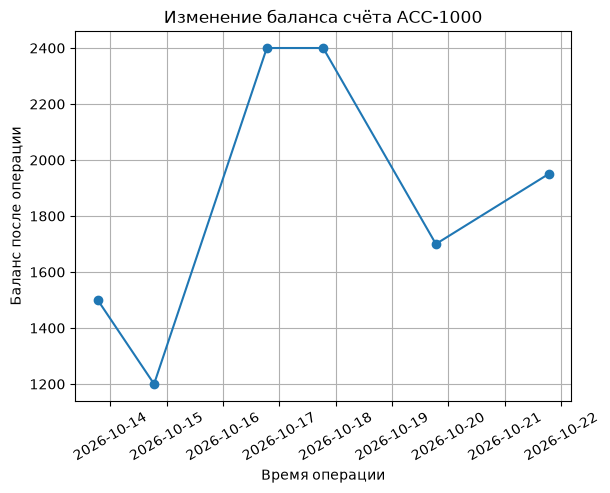

In [5]:
account.plot_balance()

# Задание 2. Разные типы счетов и аналитика
Расчётный и сберегательный счета должны отражать общее поведение учёта операций, но отличаться правилами.

Правила
Расчётный счёт - базовые пополнение и снятие без дополнительных ограничений на долю снимаемой суммы.
Сберегательный счёт: умеет начислять проценты на текущий остаток (ставку задаёт вызывающий код, например 7%); нельзя снять больше 50% текущего баланса; нарушающая правило попытка не меняет баланс и фиксируется в истории как неуспешная.
У каждого типа счёта должен быть различимый тип (чтобы по объекту/данным было понятно, расчётный это счёт или сберегательный).
Валидация имени владельца: формат «Имя Фамилия», слова с заглавной буквы, кириллица или латиница. Иначе - исключение. Для проверки используйте регулярные выражения.
Аналитика по истории: возможность получить последние N крупных успешных операций (порог «крупности» и N задаёт вызывающий код).
Демонстрация
В ноутбуке покажите:

- создание расчётного и сберегательного счета;

- покажите начисление процентов на сберегательном;

- покажите отклонение снятия сверх 50% на сберегательном;

- покажите выборку последних крупных операций;

- покажите реакцию на некорректное имя владельца и/или некорректную сумму.

In [6]:
checking = CheckingAccount("Андрей Коп", 2000)
savings = SavingsAccount("Yana Medova", 10000)
print(checking.account_type, checking.number)
print(savings.account_type, savings.number)

# Проценты
savings.add_interest(7, at(1))
print("После начисления 7%:", savings.balance)

# Снятие сверх 50 отклоняется, ровно 50 можно
print("Снять 6000:", savings.withdraw(6000, at(2)))
print("Снять 5350:", savings.withdraw(5350, at(3)))
savings.deposit(4000, at(4))
savings.deposit(1500, at(5))
savings.show_history()

checking ACC-1001
savings ACC-1002
После начисления 7%: 10700.0
Снять 6000: False
Снять 5350: True
savings ACC-1002 | Yana Medova | баланс: 10850.0
    type  amount                       time  balance_after  status transfer_id
interest   700.0 2026-10-13 18:38:33.911529        10700.0 success            
withdraw  6000.0 2026-10-14 18:38:33.911529        10700.0    fail            
withdraw  5350.0 2026-10-15 18:38:33.911529         5350.0 success            
 deposit  4000.0 2026-10-16 18:38:33.911529         9350.0 success            
 deposit  1500.0 2026-10-17 18:38:33.911529        10850.0 success            


In [7]:
# Последние 2 крупные от 1000 успешные операции
savings.last_large(1000, 2)

,type,amount,time,balance_after,status,transfer_id
3,deposit,4000.0,2026-10-16 18:38:33.911529,9350.0,success,
4,deposit,1500.0,2026-10-17 18:38:33.911529,10850.0,success,


In [8]:
for name in ["Даниил рогов", "даниил", "даниил1 rogov"]:
    try:
        CheckingAccount(name)
    except ValueError as error:
        print(error)

for amount in [-100, 0, "abc"]:
    try:
        checking.deposit(amount)
    except ValueError as error:
        print(error)

Некорректное имя владельца: 'Даниил рогов'
Некорректное имя владельца: 'даниил'
Некорректное имя владельца: 'даниил1 rogov'
Некорректная сумма: -100
Некорректная сумма: 0
Некорректная сумма: 'abc'


# Дополнительное задание. Перевод между счетами
Добавьте возможность перевода средств с одного счёта на другой:

при успехе сумма списывается у отправителя и зачисляется получателю;
если списание у отправителя невозможно (недостаточно средств или сработали ограничения сберегательного счёта), баланс получателя не меняется;
в историях обоих счетов перевод должен быть различим (например, общий идентификатор перевода, связанные записи или иной явный признак - способ выбираете вы).
Этот пункт не обязателен, но без него сложно претендовать на верхнюю часть шкалы: он показывает, насколько согласовано поведение разных счетов и насколько аккуратно продуманы связанные операции.

In [9]:
sender = CheckingAccount("Марк Денисов", 3000)
receiver = SavingsAccount("София Густова", 1000)

print(transfer(sender, receiver, 1000, at(1)))    # успех
print(transfer(receiver, sender, 1500, at(2)))    # лимит 50
print(transfer(sender, receiver, 10000, at(3)))   # не хватает средств
sender.show_history()
receiver.show_history()

True
False
False
checking ACC-1003 | Марк Денисов | баланс: 2000
    type  amount                       time  balance_after  status transfer_id
withdraw    1000 2026-10-13 18:38:33.911529           2000 success    92dac31a
withdraw   10000 2026-10-15 18:38:33.911529           2000    fail    f50beb90
savings ACC-1004 | София Густова | баланс: 2000
    type  amount                       time  balance_after  status transfer_id
 deposit    1000 2026-10-13 18:38:33.911529           2000 success    92dac31a
withdraw    1500 2026-10-14 18:38:33.911529           2000    fail    90f67152


# Задание 3. Загрузка «грязных» данных
Перед началом работы загрузите из личного кабинета файлы transactions_dirty.csv и transactions_dirty.json.

Файл общий для нескольких счетов: нужно загружать в конкретный счёт только его операции (фильтрация по номеру счёта / типу - по данным файла).

Правила
Реализуйте загрузку истории из CSV и\или из JSON.
Перед записью в историю отбрасывайте невалидные строки: опечатки в типе операции, пустые или отрицательные суммы, некорректные даты, некорректный статус и т.п.
Для сберегательного счёта допустимы типы операций deposit, withdraw, interest; для расчётного - только deposit и withdraw. Операции, недопустимые для типа счёта, невалидны.
После успешной загрузки валидных операций баланс счёта должен соответствовать последовательности принятых операций.
Демонстрация
Загрузите данные хотя бы из одного формата в расчётный и в сберегательный счёт, покажите обновлённый баланс и фрагмент истории.

In [10]:
CSV_PATH = "files/transactions_dirty.csv"
JSON_PATH = "files/transactions_dirty.json"

loaded_checking = CheckingAccount("Алексей Багаутдинов")
n_checking, bad_checking = loaded_checking.load_from_file(
    CSV_PATH, "ACC-100001")
print("Расчётный, баланс:", loaded_checking.balance)
loaded_checking.history_df().head(8)

Расчётный, баланс: 3664.0


,type,amount,time,balance_after,status,transfer_id
0,deposit,921.0,2025-09-27 22:17:26,921.0,success,
1,deposit,607.0,2025-09-27 22:17:26,1528.0,success,
2,deposit,129.0,2025-09-28 22:17:00,1657.0,success,
3,deposit,488.0,2025-09-28 22:17:26,2145.0,success,
4,deposit,880.0,2025-09-29 22:17:26,3025.0,success,
5,withdraw,352.0,2025-10-01 22:17:26,2673.0,success,
6,withdraw,65.0,2025-10-01 22:17:26,2608.0,success,
7,withdraw,245.0,2025-10-01 22:17:26,2363.0,success,


In [11]:
loaded_savings = SavingsAccount("Алексей Багаутдинов")
n_savings, bad_savings = loaded_savings.load_from_file(CSV_PATH, "ACC-100002")
print("Сберегательный, баланс:", loaded_savings.balance)
loaded_savings.history_df().head(8)

Сберегательный, баланс: 2491.24


,type,amount,time,balance_after,status,transfer_id
0,deposit,469.00,2025-09-27 22:17:26,469.00,success,
1,withdraw,392.00,2025-09-27 22:17:26,77.00,success,
2,deposit,317.00,2025-09-28 22:17:26,394.00,success,
3,deposit,840.00,2025-10-02 22:17:26,1234.00,success,
4,interest,183.28,2025-10-04 22:17:00,1417.28,success,
5,interest,192.44,2025-10-06 22:17:26,1609.72,success,
6,deposit,426.00,2025-10-08 22:17:26,2035.72,success,
7,deposit,638.00,2025-10-09 22:17:00,2673.72,success,


In [12]:
# Тот же счёт из JSON
from_json = CheckingAccount("Алексей Багаутдинов")
from_json.load_from_file(JSON_PATH, "ACC-100001")
print("Баланс из JSON:", from_json.balance)

Баланс из JSON: 3664.0


# Дополнительное задание. Отчёт об отбраковке
Помимо «молчаливого» отбрасывания мусора сформируйте явный результат очистки:

- сколько строк принято,

- сколько отклонено,

- почему отклонена каждая (или группа) строк - битая дата, пустая сумма, опечатка в типе (diposit), interest на расчётном счёте, неверный статус и т.д.

Формат отчёта на ваш выбор (список, датафрейм, печать сводки) - главное, чтобы его можно было показать в ноутбуке и по нему было понятно, что произошло с данными.

Этот пункт не обязателен, но без него сложно претендовать на верхнюю часть шкалы: он показывает зрелость работы с внешними данными, а не только «файл как-то прочитался».

In [13]:
print("Расчётный счёт: принято", n_checking, "отклонено", len(bad_checking))
print(bad_checking["reason"].value_counts())
bad_checking

Расчётный счёт: принято 17 отклонено 9
reason
операция 'interest' недопустима для счёта типа checking    2
некорректная дата                                          2
пустая или нечисловая сумма                                1
пустой тип операции                                        1
опечатка в типе операции: 'diposit'                        1
некорректный статус: 'succes'                              1
дубликат строки                                            1
Name: count, dtype: int64


,record,reason,date,operation,amount,status
0,6,пустая или нечисловая сумма,2025-09-29 22:17:26,withdraw,,success
1,9,пустой тип операции,2025-10-01 22:17:26,,654.0,success
2,11,операция 'interest' недопустима для счёта типа checking,2025-10-03 22:17:26,interest,532.0,success
3,14,некорректная дата,2025-17-34 12:00:00,deposit,793.0,success
4,16,опечатка в типе операции: 'diposit',2025-10-06 22:17:26,diposit,669.0,success
5,17,операция 'interest' недопустима для счёта типа checking,2025-10-08 22:17:26,interest,744.0,success
6,18,некорректная дата,2023-16-40 12:00:00,withdraw,111.0,success
7,25,некорректный статус: 'succes',2025-10-19 22:17:26,deposit,916.0,succes
8,105,дубликат строки,2025-10-16 22:17:26,withdraw,393.0,success


In [14]:
print("Сберегательный счёт: принято", n_savings,
      "отклонено", len(bad_savings))
print(bad_savings["reason"].value_counts())
bad_savings

Сберегательный счёт: принято 18 отклонено 9
reason
отрицательная или нулевая сумма        2
некорректный статус: 'succes'          2
некорректная дата                      1
пустая или нечисловая сумма            1
опечатка в типе операции: 'diposit'    1
опечатка в типе операции: 'wdraw'      1
дубликат строки                        1
Name: count, dtype: int64


,record,reason,date,operation,amount,status
0,29,некорректная дата,2023-22-32 12:00:00,deposit,797.0,success
1,30,пустая или нечисловая сумма,2025-09-30 22:17:26,interest,,success
2,34,отрицательная или нулевая сумма,2025-10-08 22:17:26,deposit,-136.0,success
3,38,опечатка в типе операции: 'diposit',2025-10-09 22:17:26,diposit,432.0,success
4,45,отрицательная или нулевая сумма,2025-10-16 22:17:26,deposit,-872.0,success
5,47,некорректный статус: 'succes',2025-10-19 22:17:26,withdraw,300.0,succes
6,49,опечатка в типе операции: 'wdraw',2025-10-22 22:17:26,wdraw,457.0,success
7,101,дубликат строки,09/10/2025 22:17,deposit,638.0,success
8,104,некорректный статус: 'succes',2025-10-19 22:17:26,withdraw,300.0,succes
